<a href="https://colab.research.google.com/github/himanshusingh1845/BlahBlahBlah/blob/main/FAKE_NEWS_DETECTION_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PROJECT TITLE:** *FAKE NEWS DETECTION USING TF-IDF*


---


## **PROJECT ID:** *AAI-001*
## **GROUP ID:** *BCA_AI_AdvAI_01*
## **MENTOR NAME:** *SACHIN KUMAR*

---

## **TEAM LEADER:** ADITYA SAXENA *(BCAI2024015)*

## **TEAM MEMBERS:**

*   JASPREET KAUR (BCAI2024001)


*   ASHISH PRATAP (BCAI2024002)
*   SHIKHAR GANGWAR (BCAI2024003)


*   NAMAN DEEP SINGH (BCAI2024004)
*   YASHVI SINGH (BCAI2024006)
*   ABHISHEK SINGH (BCAI2024007)
*   NANDANI SINGH (BCAI2024008)
*   SANCHITA (BCAI2024009)
*   VIBHUTI AGARWAL (BCAI2024010)
*   NATASHA JENA (BCAI2024012)
*   PEEHU CHAUDHARY (BCAI2024013)
*   HIMANSHU SINGH (BCAI2024016)
*   SURYANSH SHRIVASTAVA (BCAI2024017)




# **ABOUT PROJECT:**

> In today's digital world, news spreads rapidly through websites, social media platforms, and online publications. However, not all information available online is accurate or trustworthy.

>Fake news can mislead readers and create confusion. Therefore, identifying patterns that distinguish real and fake news has become an important application of Natural Language Processing (NLP).

>This project aims to develop a Machine Learning-based Fake News Detection System that classifies news articles as either Real or Fake using text-based features.

## **🎯 Project Objectives**
📂 Collect and analyse a labelled Fake and Real News dataset.

🧹 Clean and preprocess the news text.

🔢 Convert text into numerical features using TF-IDF.

🤖 Train Machine Learning models using Naive Bayes and Logistic Regression.

📊 Evaluate model performance using Accuracy, Precision, Recall, and F1-score.

🔍 Analyse incorrect predictions and understand model limitations.


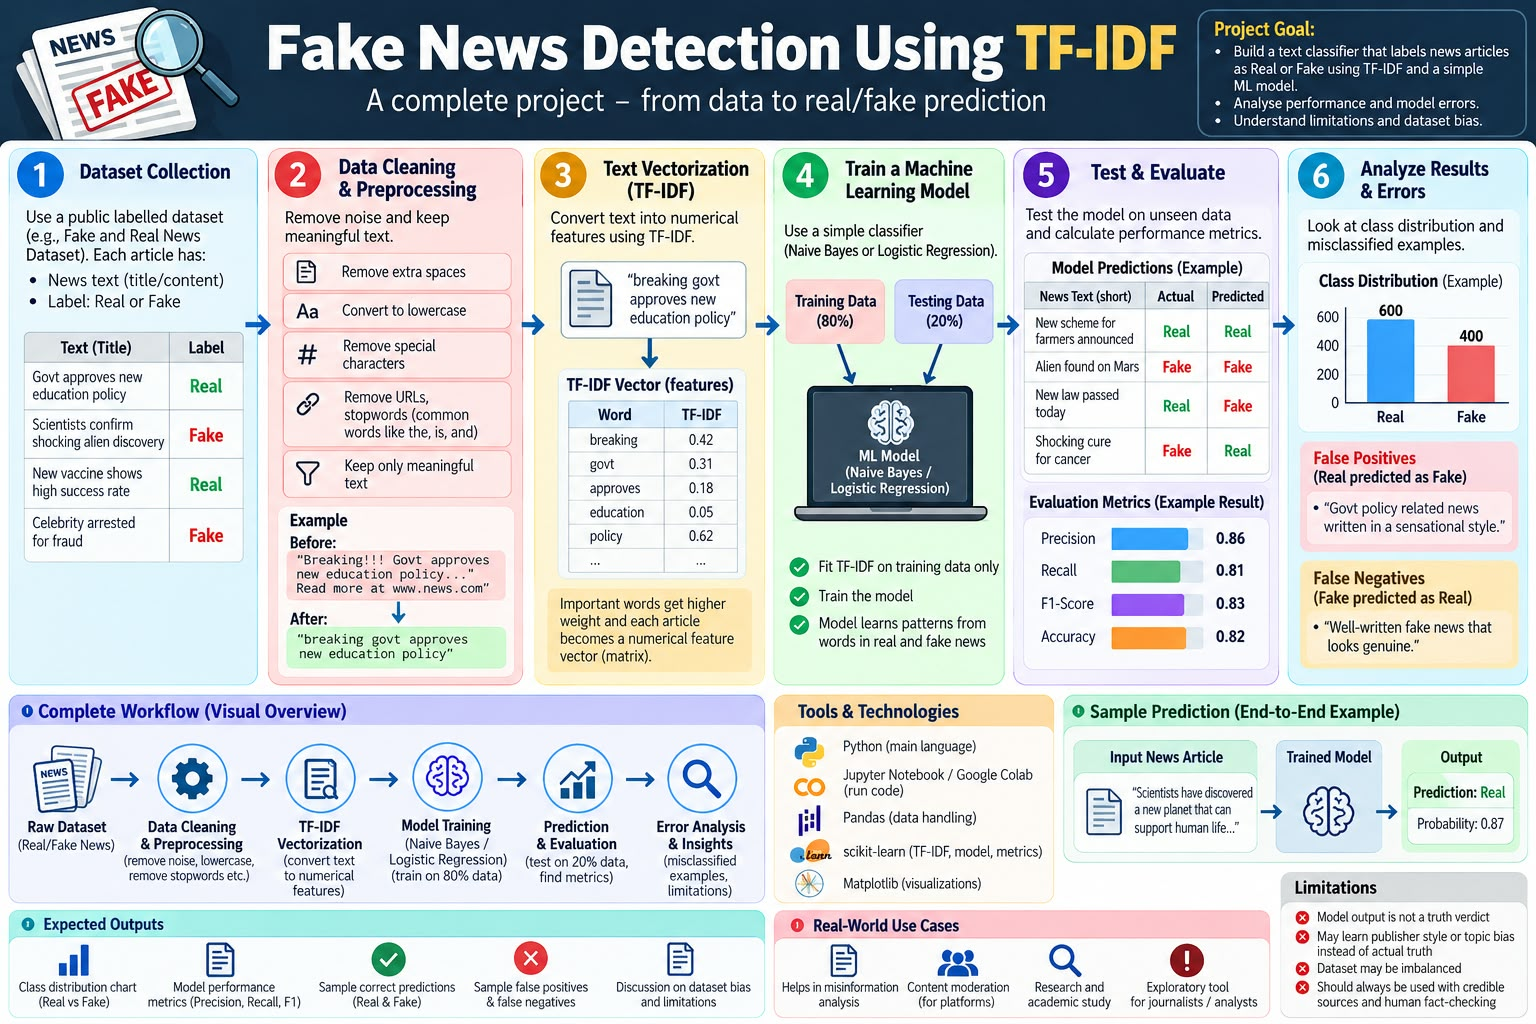

## **Project Begins**

### 📚 **STEP 1 : IMPORTING REQUIRED LIBERARIES**



In this section, we import the Python libraries required for data manipulation, text preprocessing, data visualization, machine learning, and model evaluation.

These libraries will help us perform different stages of the Fake News Detection project efficiently.




In [ ]:
# Data Handling
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text Preprocessing
import re
import string

# Machine Learning - TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

# Train-Test Split
from sklearn.model_selection import train_test_split

# Machine Learning Models
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

# Model Evaluation
from sklearn.metrics import (
accuracy_score,
precision_score,
recall_score,
f1_score,
classification_report,
confusion_matrix
)

# Ignore Warnings
import warnings
warnings.filterwarnings('ignore')


### 📂 **STEP 2 : LOADING THE DATASETS**

In this step, we will load the Fake and Real News datasets into Pandas DataFrames.

The datasets contain news articles with their respective titles, content, subject categories, and publication dates.

- **Fake Dataset:** Contains articles labelled as fake news.
- **True Dataset:** Contains articles labelled as real news.

Our goal is to load both datasets and inspect their structure before performing data preprocessing.

In [ ]:


# Load the fake news dataset
fake = pd.read_csv('/content/Fake.xls')

# Load the real news dataset
true = pd.read_csv('/content/True.xls')

# Display the shape of both datasets
print("Fake News Dataset Shape:", fake.shape)
print("Real News Dataset Shape:", true.shape)

Fake News Dataset Shape: (23481, 4)
Real News Dataset Shape: (21417, 4)


### 🔍 **STEP 3 : INITIAL DATASET INSPECTION**

Before processing the data, we need to understand its structure and contents.

In this step, we will:
- Display the first five records.
- Check the available columns.
- Understand the data types.
- Examine the overall dataset information.

This helps us identify the structure of the dataset and prepare it for further processing.

In [ ]:
# 🔍 Display the first five records of both datasets

print("FAKE NEWS DATASET:")
display(fake.head())

print("\nTRUE NEWS DATASET:")
display(true.head())

FAKE NEWS DATASET:


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"



TRUE NEWS DATASET:


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [ ]:
# 📊 Check the structure and data types of both datasets

print("FAKE NEWS DATASET INFO:")
fake.info()

print("\nTRUE NEWS DATASET INFO:")
true.info()

FAKE NEWS DATASET INFO:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    23481 non-null  object
 1   text     23481 non-null  object
 2   subject  23481 non-null  object
 3   date     23481 non-null  object
dtypes: object(4)
memory usage: 733.9+ KB

TRUE NEWS DATASET INFO:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    21417 non-null  object
 1   text     21417 non-null  object
 2   subject  21417 non-null  object
 3   date     21417 non-null  object
dtypes: object(4)
memory usage: 669.4+ KB


### 🏷️ **STEP 4 : Assigning Labels to the Dataset**

Machine Learning models require labelled data to learn and distinguish between different categories.

In our project, we have two separate datasets:
- **Fake News Dataset:** Contains articles labelled as Fake.
- **Real News Dataset:** Contains articles labelled as Real.

To make the data suitable for machine learning, we will assign numerical labels:

- `0` → Fake News
- `1` → Real News

These labels will be used as the target variable during model training and evaluation.

In [ ]:
# 🏷️ Assign numerical labels to both datasets

# Label 0 represents Fake News
fake['label'] = 0

# Label 1 represents Real News
true['label'] = 1

# Display the first five records of each dataset
print("FAKE NEWS DATASET:")
display(fake.head())

print("\nREAL NEWS DATASET:")
display(true.head())

FAKE NEWS DATASET:


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0



REAL NEWS DATASET:


,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",1
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",1
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",1


### 🔗 **STEP 5 : COMBINING FAKE AND REAL NEWS DATASET**

After assigning numerical labels, the next step is to combine both datasets into a single DataFrame.

We will use the Pandas `concat()` function to merge the Fake and Real News datasets.

This will create one unified dataset containing both categories of news articles, making it easier to perform data analysis and train our machine learning models.

####🎯 **Objective**
- Combine both datasets into one DataFrame.
- Maintain the assigned numerical labels.
- Check the total number of records.
- Verify the combined dataset structure.

In [ ]:
# 🔗 Combine Fake and Real News datasets

df = pd.concat([fake, true], axis=0, ignore_index=True)

# Display the shape of the combined dataset
print("Combined Dataset Shape:", df.shape)

# Display the first five records
display(df.head())

Combined Dataset Shape: (44898, 5)


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


## 🔀 **STEP 6 : SHUFFLING THE DATASET**

After combining both datasets, the records are arranged in their original order, with Fake News followed by Real News.

To avoid any order-related bias, we will randomly shuffle the complete dataset.

We will use Pandas `sample()` with a fixed random state to ensure reproducibility.

#### 🎯 **Objective**
- Randomly rearrange the dataset records.
- Avoid keeping Fake and Real articles in separate blocks.
- Maintain a reproducible dataset order.

In [ ]:
# 🔀 Shuffle the combined dataset

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Display the first five shuffled records
display(df.head())

# Check the updated dataset shape
print("Shuffled Dataset Shape:", df.shape)

,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


Shuffled Dataset Shape: (44898, 5)


## 📊 **STEP 7 : CHECKING CLASS DISTRIBUTION**

Before proceeding with data cleaning, it is important to understand how Fake and Real news articles are distributed in our dataset.

We will calculate the number of records in each category and visualize their distribution.

This helps us identify whether the dataset is balanced or contains class imbalance.

Fake News (0): 23481
Real News (1): 21417


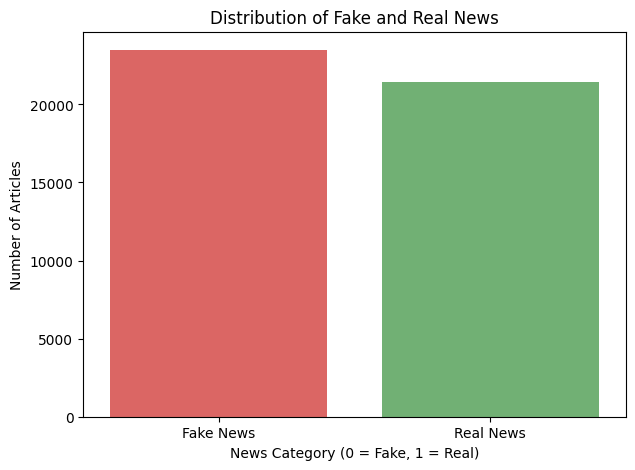

In [ ]:
# 📊 Count the number of Fake and Real News articles

label_counts = df['label'].value_counts().sort_index()

# Display category counts
print("Fake News (0):", label_counts[0])
print("Real News (1):", label_counts[1])

# Visualize class distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='label', hue='label', palette=['#EF5350', '#66BB6A'], legend=False)

plt.title("Distribution of Fake and Real News")
plt.xlabel("News Category (0 = Fake, 1 = Real)")
plt.ylabel("Number of Articles")
plt.xticks([0, 1], ['Fake News', 'Real News'])

plt.show()

## 🧹 **STEP 8 : DATA CLEANING**

Data cleaning is an important step in Machine Learning that helps improve data quality and consistency.

In this step, we will inspect and handle:

- 🔍 Missing values
- 🔁 Duplicate records
- 🗑️ Unnecessary or irrelevant data

Our goal is to prepare a clean and reliable dataset before applying text preprocessing and TF-IDF vectorization.

In [ ]:
# 🔍 Check missing values in each column

print("Missing Values in Dataset:")
print(df.isnull().sum())

Missing Values in Dataset:
title      0
text       0
subject    0
date       0
label      0
dtype: int64


In [ ]:
# 🔁 Count duplicate records

print("Total Duplicate Records:", df.duplicated().sum())

Total Duplicate Records: 209


In [ ]:
# 🧹 Remove duplicate records

df = df.drop_duplicates().reset_index(drop=True)

# Display updated dataset information
print("Dataset Shape After Removing Duplicates:", df.shape)
print("Remaining Duplicate Records:", df.duplicated().sum())

Dataset Shape After Removing Duplicates: (44689, 5)
Remaining Duplicate Records: 0


#### 🗂️ **STEP 8.2 : Selecting Relevant Columns**

The dataset contains several columns, but not all of them are required for our text classification task.

For the initial baseline model, we will use:

- `title`: The headline of the news article.
- `text`: The complete news content.
- `label`: The target category (Fake or Real).

The `subject` and `date` columns will be excluded from the initial model to focus on text-based classification.

In [ ]:
# 🗂️ Select relevant columns for the project

df = df[['title', 'text', 'label']]

# Display the updated dataset structure
print("Updated Dataset Shape:", df.shape)

# Display the first five records
display(df.head())

Updated Dataset Shape: (44689, 3)


,title,text,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",1


#### 📝 **STEP 8.3 : Combining News Title and Content**

Both the news title and article content contain useful information for classification.

In this step, we will combine these two text columns into a single column named `content`.

This combined column will be used for text preprocessing and TF-IDF feature extraction.

In [ ]:
# 📝 Combine title and news content

df['content'] = df['title'] + ' ' + df['text']

# Display sample combined records
display(df[['title', 'text', 'content', 'label']].head())

,title,text,content,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",Ben Stein Calls Out 9th Circuit Court: Committ...,0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,Trump drops Steve Bannon from National Securit...,1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,Puerto Rico expects U.S. to lift Jones Act shi...,1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",OOPS: Trump Just Accidentally Confirmed He Le...,0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",Donald Trump heads for Scotland to reopen a go...,1


## ⚙️ **STEP 9 : TEXT PREPROCESSING**

Text preprocessing is an important step in Natural Language Processing (NLP). Raw news articles may contain unnecessary characters, URLs, HTML tags, and inconsistent formatting.

In this step, we will clean the combined news text to make it suitable for machine learning.

#### 🎯 **Objectives**
- Convert all text into lowercase.
- Remove URLs and HTML tags.
- Remove unnecessary special characters.
- Remove extra whitespaces.
- Preserve meaningful words and numbers.

The cleaned text will be used for TF-IDF vectorization in the next stages.

In [ ]:
# 🧹 Function for cleaning news text

def clean_text(text): return re.sub(r'\s+', ' ', re.sub(r'[^a-zA-Z0-9\s]', ' ', re.sub(r'<.*?>', '', re.sub(r'http\S+|www\S+', '', text.lower())))).strip() if isinstance(text, str) else ""

In [ ]:
# Testing the text cleaning function

sample_text = "This is FAKE News! Visit https://example.com"

clean_text(sample_text)

'this is fake news visit'

### ⚙️ Applying the Text Cleaning Function

After defining the cleaning function, we will apply it to the combined news content column.

A new column named `cleaned_content` will store the processed text while preserving the original content for comparison.

In [ ]:
# ⚙️ Apply text cleaning to the combined news content

df['cleaned_content'] = df['content'].apply(clean_text)

# Display original and cleaned text samples
display(df[['content', 'cleaned_content']].head())

,content,cleaned_content
0,Ben Stein Calls Out 9th Circuit Court: Committ...,ben stein calls out 9th circuit court committe...
1,Trump drops Steve Bannon from National Securit...,trump drops steve bannon from national securit...
2,Puerto Rico expects U.S. to lift Jones Act shi...,puerto rico expects u s to lift jones act ship...
3,OOPS: Trump Just Accidentally Confirmed He Le...,oops trump just accidentally confirmed he leak...
4,Donald Trump heads for Scotland to reopen a go...,donald trump heads for scotland to reopen a go...


In [ ]:
# 🔍 Compare original and cleaned news text

def show_article(i): print(f"\n📰 ARTICLE {i+1}"); print("\nOriginal Text:"); print(df['content'].iloc[i][:300]); print("\nCleaned Text:"); print(df['cleaned_content'].iloc[i][:300]); print("-" * 60)

for i in range(3): show_article(i)


📰 ARTICLE 1

Original Text:
Ben Stein Calls Out 9th Circuit Court: Committed a ‘Coup d’état’ Against the Constitution 21st Century Wire says Ben Stein, reputable professor from, Pepperdine University (also of some Hollywood fame appearing in TV shows and films such as Ferris Bueller s Day Off) made some provocative statements 

Cleaned Text:
ben stein calls out 9th circuit court committed a coup d tat against the constitution 21st century wire says ben stein reputable professor from pepperdine university also of some hollywood fame appearing in tv shows and films such as ferris bueller s day off made some provocative statements on judge
------------------------------------------------------------

📰 ARTICLE 2

Original Text:
Trump drops Steve Bannon from National Security Council WASHINGTON (Reuters) - U.S. President Donald Trump removed his chief strategist Steve Bannon from the National Security Council on Wednesday, reversing his controversial decision early this year to give a pol

In [ ]:
# 📊 Check the cleaned dataset

# Count empty text records
empty_records = (df['cleaned_content'].str.strip() == '').sum()

# Check missing values
missing_values = df['cleaned_content'].isnull().sum()

print("Total Records:", len(df))
print("Empty Text Records:", empty_records)
print("Missing Cleaned Text:", missing_values)

Total Records: 44689
Empty Text Records: 9
Missing Cleaned Text: 0


### 💡 Observation

The text preprocessing function successfully standardizes the news articles by converting text into lowercase and removing URLs, HTML tags, special characters, and unnecessary whitespaces.

A new column named `cleaned_content` has been created to store the processed text.

The original news content has been preserved for comparison and verification.

This cleaned text will be used for extracting numerical features using TF-IDF.

## 🔀 **STEP 10 : SPLITTING THE DATASET INTO TRAINING AND TESTING SETS**

Before training our Machine Learning models, we need to divide the dataset into two separate parts.

- **Training Data (80%):** Used to train the Machine Learning model.
- **Testing Data (20%):** Used to evaluate the model on unseen news articles.

We will use `train_test_split()` with stratified sampling to maintain the original class distribution in both sets.

A fixed random state will ensure reproducible results.

In [ ]:
# 🎯 Separate input features and target labels

X = df['cleaned_content']
y = df['label']

# Display the shape of features and labels
print("Input Features Shape:", X.shape)
print("Target Labels Shape:", y.shape)

Input Features Shape: (44689,)
Target Labels Shape: (44689,)


In [ ]:
# 🔀 Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# 📊 Display the size of each dataset

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 35751
Testing Samples: 8938


In [ ]:
# 📊 Check label distribution in training and testing data

print("Training Data Distribution:")
print(y_train.value_counts())

print("\nTesting Data Distribution:")
print(y_test.value_counts())

Training Data Distribution:
label
0    18782
1    16969
Name: count, dtype: int64

Testing Data Distribution:
label
0    4696
1    4242
Name: count, dtype: int64


### 💡 Observation

The dataset has been successfully divided into 80% training data and 20% testing data.

Stratified sampling helps maintain the original proportion of Fake and Real News articles in both subsets.

The training data will be used to build the classification model, while the testing data will be used to evaluate its performance on unseen articles.

### 💡 Observation

The dataset has been successfully divided into 80% training data (35,751 records) and 20% testing data (8,938 records).

Stratified sampling has maintained the class distribution across both datasets, with approximately 52.5% Fake News and 47.5% Real News.

The training dataset will be used to train our machine learning models, while the testing dataset will be reserved for evaluating their performance on unseen data.

### 📌 Important Note

At this stage, we have only divided the dataset into training and testing subsets. No machine learning model has been trained yet.

Therefore, accuracy, precision, recall, and F1-score cannot be calculated at this stage.

These evaluation metrics will be calculated after training and testing our machine learning models.

## 🔢 **STEP 11 : TF-IDF VECTORIZATION**

TF-IDF (Term Frequency–Inverse Document Frequency) is a text feature extraction technique used in Natural Language Processing (NLP).

It converts textual data into numerical feature vectors that can be understood by Machine Learning algorithms.

### 🎯 **Objectives**
- Convert cleaned news articles into numerical representations.
- Identify important words based on their frequency and distribution.
- Generate TF-IDF feature matrices for training and testing data.
- Prepare the data for Machine Learning model training.

We will use Scikit-learn's `TfidfVectorizer` to perform this transformation.

**Important:** The vectorizer will be fitted only on training data to prevent data leakage.


In [ ]:
# 🔢 Initialize the TF-IDF Vectorizer

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))




print("TF-IDF Vectorizer Initialized Successfully!")

TF-IDF Vectorizer Initialized Successfully!


In [ ]:
# 🧠 Learn vocabulary and transform training text

X_train_tfidf = tfidf.fit_transform(X_train)

# Display the shape of the training feature matrix
print("Training TF-IDF Matrix Shape:", X_train_tfidf.shape)

Training TF-IDF Matrix Shape: (35751, 5000)


In [ ]:
# 🔄 Transform testing data using the learned vocabulary

X_test_tfidf = tfidf.transform(X_test)

# Display the shape of the testing feature matrix
print("Testing TF-IDF Matrix Shape:", X_test_tfidf.shape)

Testing TF-IDF Matrix Shape: (8938, 5000)


In [ ]:
# 🔍 Display some extracted vocabulary features

feature_names = tfidf.get_feature_names_out()

print("Total Extracted Features:", len(feature_names))

print("\nFirst 20 Features:")
print(feature_names[:20])

Total Extracted Features: 5000

First 20 Features:
['000' '000 people' '10' '100' '100 000' '11' '12' '13' '14' '15' '16'
 '17' '18' '19' '20' '200' '2001' '2005' '2006' '2007']


In [ ]:
# 📊 Display a small sample of TF-IDF numerical values

tfidf_sample = pd.DataFrame(X_train_tfidf[:5, :10].toarray(),columns=feature_names[:10])




display(tfidf_sample)

,000,000 people,10,100,100 000,11,12,13,14,15
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.077179,0.0,0.0


### 💡 Observation

TF-IDF vectorization successfully converts the cleaned news articles into numerical feature representations.

The vectorizer learns its vocabulary and inverse document frequency weights from the training data and applies the same transformation to the testing data.

A maximum of 5,000 text features are selected, including individual words and two-word combinations.

These numerical feature matrices will serve as input for our Machine Learning classifiers.

## 🤖 **STEP 12 : TRAINING THE NAIVE BAYES CLASSIFIER**

Naive Bayes is a supervised Machine Learning algorithm based on Bayes' Theorem.

It is widely used for text classification tasks because it performs efficiently with numerical text features such as TF-IDF.

In this step, we will train a Multinomial Naive Bayes classifier using our TF-IDF training features.

### 🎯 **Objectives**
- Initialize the Multinomial Naive Bayes classifier.
- Train the model using TF-IDF training data.
- Learn patterns associated with Fake and Real News.
- Generate predictions on the testing dataset.

The trained model will be evaluated in the next stage using standard classification metrics.

In [ ]:
# 🤖 Initialize the Multinomial Naive Bayes classifier

nb_model = MultinomialNB()

print("Naive Bayes Model Initialized Successfully!")

Naive Bayes Model Initialized Successfully!


In [ ]:
# 🚀 Train the Naive Bayes model using training data

nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes Model Trained Successfully!")

Naive Bayes Model Trained Successfully!


In [ ]:
# 🔮 Predict labels for unseen testing data

y_pred_nb = nb_model.predict(X_test_tfidf)

# Display the first 10 predictions
print("First 10 Model Predictions:")
print(y_pred_nb[:10])

print("\nFirst 10 Actual Labels:")
print(y_test.iloc[:10].values)

First 10 Model Predictions:
[1 1 1 0 1 0 0 0 0 1]

First 10 Actual Labels:
[1 1 1 0 1 0 0 0 0 1]


In [ ]:
# 📊 Compare actual and predicted labels

nb_results = pd.DataFrame({ 'Actual Label': y_test.values,'Predicted Label': y_pred_nb})




# Convert numerical labels into readable categories

nb_results['Actual News'] = nb_results['Actual Label'].map({0: 'Fake', 1: 'Real'})

nb_results['Predicted News'] = nb_results['Predicted Label'].map({0: 'Fake', 1: 'Real'})

# Display sample predictions

display(nb_results.head(10))

,Actual Label,Predicted Label,Actual News,Predicted News
0,1,1,Real,Real
1,1,1,Real,Real
2,1,1,Real,Real
3,0,0,Fake,Fake
4,1,1,Real,Real
5,0,0,Fake,Fake
6,0,0,Fake,Fake
7,0,0,Fake,Fake
8,0,0,Fake,Fake
9,1,1,Real,Real


### 💡 Observation

The Multinomial Naive Bayes classifier has been successfully trained using the TF-IDF training feature matrix.

The trained model generates predictions for the unseen testing dataset and classifies each news article into Fake or Real categories.

The actual and predicted labels are displayed for comparison.

The model's performance will be measured in the next stage using Accuracy, Precision, Recall, F1-score, and a Confusion Matrix.

## 🤖 **STEP 13 : TRAINING THE LOGISTIC REGRESSION CLAASIFIER**

Logistic Regression is a supervised Machine Learning algorithm commonly used for binary classification problems.

It estimates the probability of an input belonging to a particular class and classifies it accordingly.

In our project, Logistic Regression will be used to classify news articles into Fake or Real categories using TF-IDF features.

### 🎯 **Objectives**
- Initialize the Logistic Regression classifier.
- Train the model using TF-IDF training features.
- Generate predictions on unseen testing data.
- Prepare results for comparison with Naive Bayes.

This model will help us evaluate whether Logistic Regression performs better than our first classifier.

In [ ]:
# 🤖 Initialize the Logistic Regression classifier

lr_model = LogisticRegression(max_iter=1000,random_state=42)




print("Logistic Regression Model Initialized Successfully!")

Logistic Regression Model Initialized Successfully!


In [ ]:
# 🚀 Train the Logistic Regression model

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [ ]:
# 🔮 Generate predictions on unseen testing data

y_pred_lr = lr_model.predict(X_test_tfidf)

# Display first 10 predictions
print("First 10 Model Predictions:")
print(y_pred_lr[:10])

print("\nFirst 10 Actual Labels:")
print(y_test.iloc[:10].values)

First 10 Model Predictions:
[1 1 1 0 1 0 0 0 0 1]

First 10 Actual Labels:
[1 1 1 0 1 0 0 0 0 1]


In [ ]:
# 📊 Create a comparison table

lr_results = pd.DataFrame({'Actual Label': y_test.values,'Predicted Label': y_pred_lr})




# Convert numerical labels into readable categories

lr_results['Actual News'] = lr_results['Actual Label'].map({0: 'Fake', 1: 'Real'})

lr_results['Predicted News'] = lr_results['Predicted Label'].map({0: 'Fake', 1: 'Real'})

# Display first 10 predictions

display(lr_results.head(10))

,Actual Label,Predicted Label,Actual News,Predicted News
0,1,1,Real,Real
1,1,1,Real,Real
2,1,1,Real,Real
3,0,0,Fake,Fake
4,1,1,Real,Real
5,0,0,Fake,Fake
6,0,0,Fake,Fake
7,0,0,Fake,Fake
8,0,0,Fake,Fake
9,1,1,Real,Real


### 💡 Observation

The Logistic Regression classifier has been successfully trained using the TF-IDF training feature matrix.

The trained model generates predictions on the unseen testing dataset and classifies news articles into Fake or Real categories.

The actual and predicted labels are displayed for initial comparison.

The model's overall performance will be evaluated and compared with the Naive Bayes classifier using standard classification metrics.

## 📊 **STEP 14 : MODEL EVALUATION AND PERFORMANCE COMPARISION**

After training both Machine Learning models, we need to evaluate their performance using the unseen testing dataset.

In this step, we will compare the Multinomial Naive Bayes and Logistic Regression classifiers using standard evaluation metrics.

### 🎯 **Evaluation Metrics**

- **Accuracy:** Measures the overall percentage of correct predictions.
- **Precision:** Measures how many articles predicted as Fake are actually Fake.
- **Recall:** Measures how many actual Fake articles are correctly identified.
- **F1-Score:** Represents the balance between Precision and Recall.

We will also use a Confusion Matrix to understand the classification results.

The objective is to identify which model performs better on our testing dataset.

In [ ]:
# 🔍 Check whether model predictions are available

print("Naive Bayes:", type(y_pred_nb))
print("Logistic Regression:", type(y_pred_lr))
print("Actual Labels:", type(y_test))

Naive Bayes: <class 'numpy.ndarray'>
Logistic Regression: <class 'numpy.ndarray'>
Actual Labels: <class 'pandas.core.series.Series'>


In [ ]:
# 📊 Calculate performance metrics for both models

results = []

# Evaluate Naive Bayes
results.append({'Model': 'Naive Bayes', 'Accuracy': accuracy_score(y_test, y_pred_nb), 'Precision': precision_score(y_test, y_pred_nb, pos_label=0), 'Recall': recall_score(y_test, y_pred_nb, pos_label=0), 'F1-Score': f1_score(y_test, y_pred_nb, pos_label=0)})

# Evaluate Logistic Regression
results.append({'Model': 'Logistic Regression', 'Accuracy': accuracy_score(y_test, y_pred_lr), 'Precision': precision_score(y_test, y_pred_lr, pos_label=0), 'Recall': recall_score(y_test, y_pred_lr, pos_label=0), 'F1-Score': f1_score(y_test, y_pred_lr, pos_label=0)})

# Create comparison DataFrame
results_df = pd.DataFrame(results)

# Display model performance comparison
print("📊 Model Performance Comparison:")
print(results_df.to_string(index=False))

📊 Model Performance Comparison:
              Model  Accuracy  Precision   Recall  F1-Score
        Naive Bayes  0.950101   0.953672 0.951235  0.952452
Logistic Regression  0.990714   0.993158 0.989140  0.991145


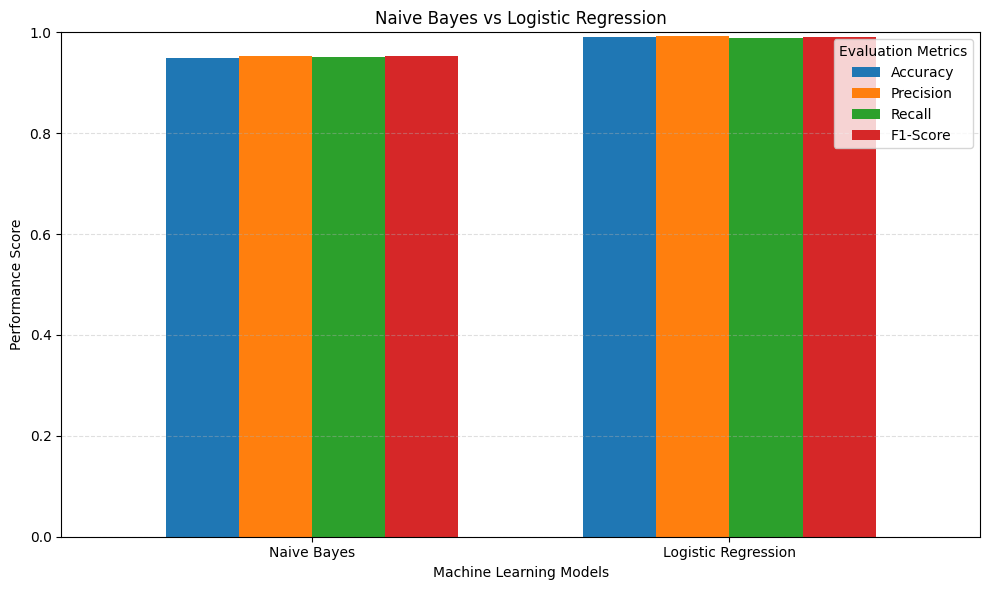

In [ ]:
# 📊 Visualize performance comparison

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

comparison = results_df.set_index('Model')[metrics]

# Create a bar chart

comparison.plot(kind='bar', figsize=(10, 6), ylim=(0, 1), width=0.7)

# Add chart labels and formatting

plt.title("Naive Bayes vs Logistic Regression")
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis='y', linestyle='--', alpha=0.4)

# Adjust layout and display chart

plt.tight_layout()
plt.show()

### 💡 Observation

The performance comparison shows that Logistic Regression performs better than Multinomial Naive Bayes across all four evaluation metrics.

Logistic Regression achieves higher Accuracy, Precision, Recall, and F1-Score on the testing dataset.

Based on these initial results, Logistic Regression appears to be the better-performing classifier for this dataset.

However, further analysis using confusion matrices and misclassified examples is required to understand the model's limitations and prediction errors.

### 📋 STEP 14.3 Detailed Classification Reports

In this step, we will generate detailed classification reports for both Machine Learning models.

The classification report provides:
- **Precision:** Correct Fake News predictions out of all Fake News predictions.
- **Recall:** Correctly identified Fake News articles out of all actual Fake News articles.
- **F1-Score:** Harmonic mean of Precision and Recall.
- **Support:** Total number of actual samples in each category.

These reports will help us understand the performance of both classifiers for individual news categories.

In [ ]:
# 📋 Generate classification reports for both models

# Naive Bayes Classification Report
print("🔵 NAIVE BAYES CLASSIFICATION REPORT")
print("=" * 55)

print(classification_report(y_test, y_pred_nb, target_names=['Fake News', 'Real News'], digits=4))

# Logistic Regression Classification Report
print("\n🟢 LOGISTIC REGRESSION CLASSIFICATION REPORT")
print("=" * 55)

print(classification_report(y_test, y_pred_lr, target_names=['Fake News', 'Real News'], digits=4))

🔵 NAIVE BAYES CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Fake News     0.9537    0.9512    0.9525      4696
   Real News     0.9462    0.9488    0.9475      4242

    accuracy                         0.9501      8938
   macro avg     0.9499    0.9500    0.9500      8938
weighted avg     0.9501    0.9501    0.9501      8938


🟢 LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Fake News     0.9932    0.9891    0.9911      4696
   Real News     0.9880    0.9925    0.9902      4242

    accuracy                         0.9907      8938
   macro avg     0.9906    0.9908    0.9907      8938
weighted avg     0.9907    0.9907    0.9907      8938



### 🔍 14.4 Confusion Matrix Analysis

A Confusion Matrix is used to evaluate the classification performance of a Machine Learning model.

It compares actual labels with predicted labels and shows:

- **True Positive (TP):** Correctly predicted positive class.
- **True Negative (TN):** Correctly predicted negative class.
- **False Positive (FP):** Real News incorrectly classified as Fake News.
- **False Negative (FN):** Fake News incorrectly classified as Real News.

In our project, Fake News (0) is treated as the positive class for this analysis.

We will generate and visualize confusion matrices for both classifiers to understand their prediction errors.

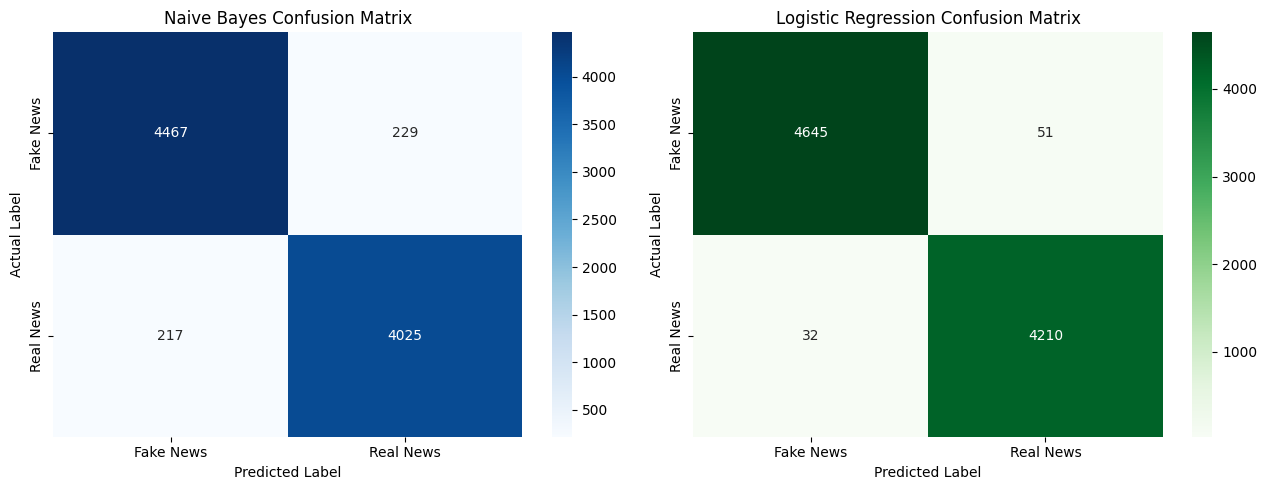

In [ ]:
# 🔍 Generate confusion matrices for both models

# Calculate confusion matrices
cm_nb = confusion_matrix(y_test, y_pred_nb)
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Create side-by-side visualizations
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 🔵 Naive Bayes Confusion Matrix
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues', xticklabels=['Fake News', 'Real News'], yticklabels=['Fake News', 'Real News'], ax=axes[0])

axes[0].set_title("Naive Bayes Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

# 🟢 Logistic Regression Confusion Matrix
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Greens', xticklabels=['Fake News', 'Real News'], yticklabels=['Fake News', 'Real News'], ax=axes[1])

axes[1].set_title("Logistic Regression Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

# Display both matrices
plt.tight_layout()
plt.show()

### 💡 Observation

The Confusion Matrix analysis shows that Logistic Regression performs better than Multinomial Naive Bayes.

Naive Bayes produced 446 incorrect predictions, whereas Logistic Regression produced only 83 incorrect predictions on the testing dataset.

Logistic Regression also identified more Fake and Real News articles correctly, with fewer false positives and false negatives.

Based on these results, Logistic Regression is the better-performing model in our current experiment.

## 🚨 **STEP 15 : ERROR ANALYSIS**

Error Analysis helps us understand the mistakes made by a Machine Learning model.

Even a model with high accuracy can make incorrect predictions.

In this step, we will examine the misclassified news articles produced by our Logistic Regression classifier.

### 🎯 **Objectives**

- Identify False Positives (Real News predicted as Fake).
- Identify False Negatives (Fake News predicted as Real).
- Inspect incorrectly classified news articles.
- Understand possible reasons behind model errors.

This analysis will help us identify the limitations and potential biases of our classification system.

In [ ]:
# 🚨 Identify incorrect predictions made by Logistic Regression
error_df = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred_lr, 'News': X_test.values}); false_positives = error_df[(error_df['Actual'] == 1) & (error_df['Predicted'] == 0)]; false_negatives = error_df[(error_df['Actual'] == 0) & (error_df['Predicted'] == 1)]; print("False Positives:", len(false_positives)); print("False Negatives:", len(false_negatives))

False Positives: 32
False Negatives: 51


In [ ]:
# 🔴 Display Real News incorrectly predicted as Fake

print("FALSE POSITIVE EXAMPLES")

display(false_positives[['News']].head(5))



FALSE POSITIVE EXAMPLES


,News
422,graphic supreme court roundup
801,in their best red stilettos german transvestit...
868,a young chinese rebel feels the pull of family...
994,hacked emails show clinton aides surprised at ...
1693,qu bol obama jokes with cuban humorist in vide...


In [ ]:
# 🔍 Display complete False Negative examples
print("🟡 FALSE NEGATIVE EXAMPLES"); print("=" * 60)
for i, row in false_negatives.head(5).iterrows(): print(f"\nArticle {i}"); print("Actual Label: Fake News"); print("Predicted Label: Real News"); print("\nNews Content:"); print(row['News']); print("-" * 60)

🟡 FALSE NEGATIVE EXAMPLES

Article 287
Actual Label: Fake News
Predicted Label: Real News

News Content:
breaking iran publicly humiliates obama unveils second underground missile capable of carrying nuclear warhead a clear violation of obama s lopsided deal with iran hey barry do you still think iran wants to be our friend what was the rush for america to cave to iran while totally ignoring their nuclear ambitions iran unveiled a new underground missile depot on tuesday with state television showing emad precision guided missiles in store which the united states says can take a nuclear warhead and violate a 2010 u n security council resolution the defiant move to publicize iran s missile program seemed certain to irk the united states as it plans to dismantle nearly all sanctions on iran under a breakthrough nuclear agreement tasnim news agency and state television video said the underground facility situated in mountains and run by iran s revolutionary guards was inaugurated by the s

In [ ]:
# 🔴 Display complete False Positive examples
print("🔴 FALSE POSITIVE EXAMPLES"); print("=" * 60)
for i, row in false_positives.head(5).iterrows(): print(f"\nArticle {i}"); print("Actual Label: Real News"); print("Predicted Label: Fake News"); print("\nNews Content:"); print(row['News']); print("-" * 60)

🔴 FALSE POSITIVE EXAMPLES

Article 422
Actual Label: Real News
Predicted Label: Fake News

News Content:
graphic supreme court roundup
------------------------------------------------------------

Article 801
Actual Label: Real News
Predicted Label: Fake News

News Content:
in their best red stilettos german transvestites stomp on afd berlin reuters german drag queens are using satire to spoof a hard right party s anti islam election campaign and german voters are loving it they have formed transvestites for germany or tfd a name that bears an uncanny resemblance to alternative for germany afd the name of germany s leading right wing party and launched a facebook campaign that has almost 7 000 followers the afd s election campaign focuses on messages that islamic customs don t belong in germany that has left a bad taste with many germans and tfd saw an opportunity to use drag fashion and wit to mock the afd s own election placards the afd posters feature white german women in bikinis o

### 💡 Observation

The error analysis identified 32 False Positives and 51 False Negatives in the Logistic Regression model.

False Positives occurred when genuine news articles were incorrectly classified as Fake, while False Negatives occurred when Fake News articles were incorrectly classified as Real.

The inspected examples suggest that political topics, sensational language, and professional news-writing styles may create challenges for text-based classification.

These findings highlight that high model accuracy does not guarantee factual verification. Dataset bias and writing-style patterns may influence the model's predictions.

## ⚠️ **STEP 16 : DATASET BOAS AND MODEL LIMITATIONS**

Although our Machine Learning models achieved good performance on the testing dataset, their predictions may be influenced by limitations in the dataset and text-based classification approach.

Understanding these limitations is important before considering real-world applications.

### 🔍 **1. Dataset Age**
The dataset contains news articles primarily from 2017. Therefore, it may not represent current news topics, writing styles, or modern misinformation techniques.

### 📰 **2. Publisher and Source Bias**
The model may learn patterns associated with specific publishers or news sources instead of identifying factual accuracy.

### 📝 **3. Writing Style Bias**
Fake news written in a professional style may be classified as Real, while genuine news written in a sensational style may be classified as Fake.

### ⚖️ **4. Topic Bias**
Differences in topics between Fake and Real News articles may influence the predictions.

### 📊 **5. Dataset Limitations**
The dataset contains labelled examples, but these labels do not independently guarantee the factual correctness of every article.

### 🚫 **6. No Independent Fact Verification**
The model identifies patterns in text. It does not verify claims against trusted sources or independently establish whether an article is true.

### 💡 **Conclusion**
The system should be considered an exploratory text classification tool rather than an authoritative Fake News verification system.

### 📌 **Summary of Dataset Limitations**

| Limitation | Possible Impact |
|---|---|
| Old Dataset (2017) | May not represent current news patterns |
| Publisher Bias | Model may learn source-specific patterns |
| Topic Bias | Certain topics may influence predictions |
| Writing Style | Sensational or professional language may mislead the model |
| Label Dependency | Predictions depend on the quality of original dataset labels |
| No Fact Checking | Model cannot independently verify news claims |

These limitations should be considered when interpreting the model's performance and applying it to real-world situations.

## 🧪 **STEP 17 : TESTING THE MODEL WITH NEW NEWS ARTICLES**

After training and evaluating our classifiers, we will test the selected Logistic Regression model using new text inputs.

The system will:
- Accept a news headline or article from the user.
- Apply the same text preprocessing steps.
- Convert the cleaned text into TF-IDF features.
- Generate a prediction using the trained classifier.
- Display the predicted category and model confidence.

This demonstrates how the trained model can be used for basic text classification.

**Note:** The prediction represents the model's learned classification pattern, not an independent verification of factual accuracy.

In [ ]:
# 🔮 Function to predict whether news resembles Fake or Real

def predict_news(news_text): cleaned_news = clean_text(news_text); news_vector = tfidf.transform([cleaned_news]); prediction = lr_model.predict(news_vector)[0]; probabilities = lr_model.predict_proba(news_vector)[0]; confidence = max(probabilities) * 100; result = "Fake News" if prediction == 0 else "Real News"; print("📋 News Classification Result"); print("-" * 40); print("Prediction:", result); print(f"Model Confidence: {confidence:.2f}%"); print("-" * 40); print("⚠️ This is a model prediction, not factual verification."); return result

In [ ]:
# 🧪 Test the trained model with sample news

sample_news = """
The government announced a new education policy
to improve learning opportunities for students.
"""

# Generate prediction
predict_news(sample_news)

📋 News Classification Result
----------------------------------------
Prediction: Fake News
Model Confidence: 69.64%
----------------------------------------
⚠️ This is a model prediction, not factual verification.


'Fake News'

In [ ]:

# Sample news input
user_news = """
The government announced a new initiative to improve
digital education facilities in schools across the country.
The programme aims to provide students with better access
to online learning resources and modern technology.
Officials stated that the initiative will be implemented
in multiple phases over the coming months.
"""

# Generate prediction
predict_news(user_news)


📋 News Classification Result
----------------------------------------
Prediction: Fake News
Model Confidence: 75.36%
----------------------------------------
⚠️ This is a model prediction, not factual verification.


'Fake News'

In [ ]:
user_news = """
Scientists have developed a new battery technology
that can store more energy and charge faster.
Researchers believe this innovation could improve
electric vehicles and renewable energy storage.
The technology is currently undergoing further testing.
"""

predict_news(user_news)

📋 News Classification Result
----------------------------------------
Prediction: Fake News
Model Confidence: 85.71%
----------------------------------------
⚠️ This is a model prediction, not factual verification.


'Fake News'

## 🎯 **STEP 18 : PROJECT CONCLUSION**

In this project, we developed a Fake News Detection system using Machine Learning and Natural Language Processing (NLP).

The project uses TF-IDF Vectorization to convert textual news data into numerical features. Two machine learning algorithms, Multinomial Naive Bayes and Logistic Regression, were trained and evaluated.

### **Key Findings**
- Data cleaning and preprocessing improved the quality of the dataset.
- TF-IDF was used to extract important textual features.
- Logistic Regression performed better than Multinomial Naive Bayes on the test dataset.
- The trained model can classify user-provided news text as Fake or Real.

### **Limitations**
- The model depends on patterns learned from the training dataset.
- Dataset bias and outdated information may affect predictions.
- The system does not independently verify news facts or sources.

### **Future Scope**
- Use larger and more diverse datasets.
- Apply advanced NLP techniques such as BERT.
- Include source credibility and fact-checking mechanisms.
- Develop a web-based application for real-time news classification.

### **Final Conclusion**
The project demonstrates how Machine Learning and NLP techniques can be used for automated news text classification. However, its predictions should be treated as preliminary indicators rather than factual verification.